<a href="https://colab.research.google.com/github/Utkarsh-sengar3/AI-ML-Learning/blob/main/Unsupervised-Learning/Untitled2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Original Dataset shape :  (5000, 784)
Compressed dataset shape:  (5000, 252)


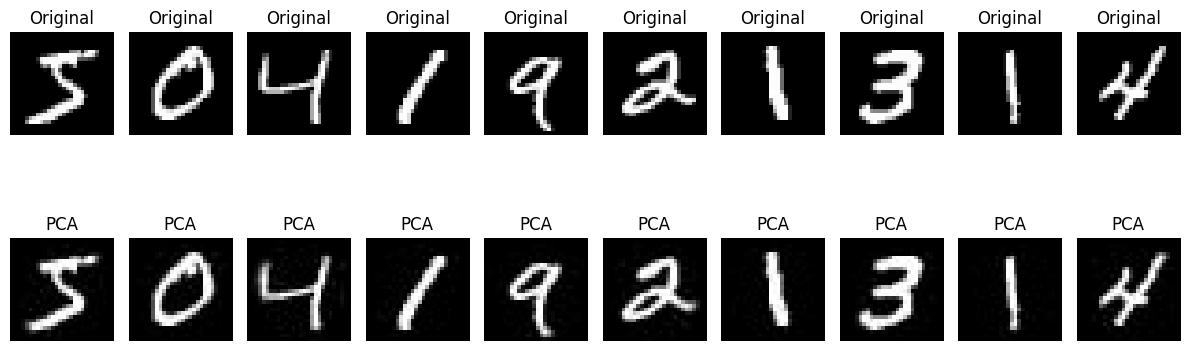

Original Features:  784
Compressed Features:  252
Explained variance ratio:  0.9801


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml
from sklearn.decomposition import PCA

#Load MNIST dataset
mnist = fetch_openml(
    "mnist_784",
    version=1,
    as_frame=False
)

X= mnist.data

#Use a subset to make execution faster
#Select the first 5000 images to reduce execution time
X=X[:5000]

print("Original Dataset shape : ", X.shape)

#4. Normalise pixel values between 0 to 1
X=X/255.0

#5. Apply PCA
pca = PCA(n_components=0.98)

#6. Fit PCA and reduce dimensions
X_compressed = pca.fit_transform(X)

print("Compressed dataset shape: ",X_compressed.shape)

#7. Reconstruct the images
X_reconstructed = pca.inverse_transform(X_compressed)

#8. Display original and reconstructed images
plt.figure(figsize=(12,5))

for i in range(10):
  #Original Image
  plt.subplot(2,10,i+1)
  plt.imshow(X[i].reshape(28,28),cmap="gray")
  plt.title("Original")
  plt.axis("off")

  #Reconstructed Image
  plt.subplot(2,10,i+11)
  plt.imshow(X_reconstructed[i].reshape(28,28),cmap="gray",vmin=0,vmax=1)
  plt.title("PCA")
  plt.axis("off")
plt.tight_layout()
plt.show()

#Display compression information
print("Original Features: ", X.shape[1])
print("Compressed Features: ", pca.n_components_)
print("Explained variance ratio: ", round(pca.explained_variance_ratio_.sum(),4))

#Calculate Dimensionality reduction